# 02b · Train the basic CNN baseline (80 epochs)

The simplest possible segmentation network, as a baseline for MANet: one 3×3 conv + ReLU per stage, 3 max-pools down, 3 transposed convs back up. **No skip connections, no normalization, no attention.** 0.28M parameters.

Binary segmentation (pet vs background) on Oxford-IIIT Pet, cats **and** dogs.
Same data, augmentation, loss, optimizer and schedule for every model so results are comparable.
The best checkpoint by validation Dice is saved to `checkpoints/basiccnn_e80_pets_best.pt`.

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

from manet_lib import (
    read_pet_list, split_train_val, PetSegDataset, build_model, count_params, MODELS,
    DiceBCELoss, run_epoch, predict_dataset, denormalize, overlay,
)

ROOT = Path("data/oxford-iiit-pet")
MODEL_NAME = "BasicCNN"   # "MANet" | "MANet_small" | "MANet_small_small" | "BasicCNN"
IMG_SIZE = 256
BATCH_SIZE = 16
NUM_WORKERS = 6
EPOCHS = 80
MAX_LR = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 15                 # early stop if val Dice doesn't improve for this many epochs
SEED = 42
RUN_TAG = f"{MODEL_NAME.lower()}_e{EPOCHS}"
CKPT_PATH = Path(f"checkpoints/{RUN_TAG}_pets_best.pt")
HISTORY_PATH = Path(f"outputs/{RUN_TAG}_history.csv")
CKPT_PATH.parent.mkdir(exist_ok=True); HISTORY_PATH.parent.mkdir(exist_ok=True)

torch.manual_seed(SEED); np.random.seed(SEED)
torch.backends.cudnn.benchmark = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
print("Run:", RUN_TAG)

Device: cuda NVIDIA GeForce RTX 5080 Laptop GPU
Run: basiccnn_e80


In [2]:
trainval = read_pet_list(ROOT, "trainval")
train_rows, val_rows = split_train_val(trainval, val_frac=0.15, seed=SEED)

train_ds = PetSegDataset(ROOT, train_rows, IMG_SIZE, train=True)
val_ds = PetSegDataset(ROOT, val_rows, IMG_SIZE, train=False)

loader_kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(train_ds, shuffle=True, drop_last=True, **loader_kw)
val_loader = DataLoader(val_ds, shuffle=False, **loader_kw)
print(f"train={len(train_ds)} images ({len(train_loader)} batches)  val={len(val_ds)} images")

xb, yb, meta = next(iter(train_loader))
print("X:", tuple(xb.shape), xb.dtype, " Y:", tuple(yb.shape), yb.dtype)

train=3129 images (195 batches)  val=551 images


X: (16, 3, 256, 256) torch.float32  Y: (16, 1, 256, 256) torch.float32


## Model size comparison

In [3]:
pd.DataFrame([{"model": n, "params (M)": round(count_params(c()) / 1e6, 3)} for n, c in MODELS.items()])

,model,params (M)
0,MANet,33.399
1,MANet_small,8.287
2,MANet_small_small,2.075
3,BasicCNN,0.284


In [4]:
model = build_model(MODEL_NAME, n_channels=3, n_classes=1).to(device)
criterion = DiceBCELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=MAX_LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=MAX_LR, epochs=EPOCHS, steps_per_epoch=len(train_loader))

print(f"{MODEL_NAME}: {count_params(model):,} trainable params")
with torch.no_grad():
    print("Forward OK:", tuple(model(xb[:2].to(device)).shape))

BasicCNN: 283,969 trainable params


Forward OK: (2, 1, 256, 256)


## Train

In [5]:
history = []
best_dice, best_epoch, bad_epochs = -1.0, -1, 0
train_start = time.time()

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr = run_epoch(model, train_loader, criterion, optimizer, scheduler, device=device)
    va = run_epoch(model, val_loader, criterion, device=device)
    history.append({"epoch": epoch, "lr": scheduler.get_last_lr()[0], "seconds": time.time() - t0,
                    **{f"train_{k}": v for k, v in tr.items()}, **{f"val_{k}": v for k, v in va.items()}})

    improved = va["dice"] > best_dice + 1e-4
    if improved:
        best_dice, best_epoch, bad_epochs = va["dice"], epoch, 0
        torch.save({"model": model.state_dict(), "model_name": MODEL_NAME, "img_size": IMG_SIZE,
                    "epoch": epoch, "epochs": EPOCHS, "val_dice": best_dice}, CKPT_PATH)
    else:
        bad_epochs += 1

    print(f"epoch {epoch:03d} | {time.time() - t0:5.1f}s | "
          f"train loss {tr['loss']:.4f} dice {tr['dice']:.4f} | "
          f"val loss {va['loss']:.4f} dice {va['dice']:.4f} iou {va['iou']:.4f} acc {va['acc']:.4f}"
          + ("  *saved*" if improved else ""))

    if bad_epochs >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
print(f"Best val Dice {best_dice:.4f} at epoch {best_epoch} -> {CKPT_PATH}")
print(f"Total training time: {(time.time() - train_start) / 60:.1f} min")

epoch 001 |  17.5s | train loss 1.1952 dice 0.3200 | val loss 1.2876 dice 0.5608 iou 0.4118 acc 0.4119  *saved*


epoch 002 |   8.6s | train loss 1.1490 dice 0.6642 | val loss 1.2651 dice 0.5687 iou 0.4198 acc 0.4351  *saved*


epoch 003 |   8.9s | train loss 1.1242 dice 0.6777 | val loss 1.2117 dice 0.5965 iou 0.4469 acc 0.5217  *saved*


epoch 004 |   9.0s | train loss 1.0741 dice 0.6951 | val loss 1.1411 dice 0.6321 iou 0.4845 acc 0.5920  *saved*


epoch 005 |   9.2s | train loss 1.0179 dice 0.7072 | val loss 1.0999 dice 0.6430 iou 0.4962 acc 0.6118  *saved*


epoch 006 |   9.1s | train loss 0.9907 dice 0.7067 | val loss 0.9861 dice 0.6838 iou 0.5396 acc 0.7062  *saved*


... (70 outputs left out)

epoch 077 |   9.5s | train loss 0.4897 dice 0.8620 | val loss 0.5541 dice 0.8273 iou 0.7224 acc 0.8592


epoch 078 |   9.7s | train loss 0.4862 dice 0.8634 | val loss 0.5501 dice 0.8283 iou 0.7236 acc 0.8607


epoch 079 |   9.7s | train loss 0.4917 dice 0.8618 | val loss 0.5500 dice 0.8283 iou 0.7236 acc 0.8607


epoch 080 |  10.1s | train loss 0.4883 dice 0.8633 | val loss 0.5499 dice 0.8283 iou 0.7237 acc 0.8607
Best val Dice 0.8329 at epoch 75 -> checkpoints\basiccnn_e80_pets_best.pt
Total training time: 12.6 min


## Training curves

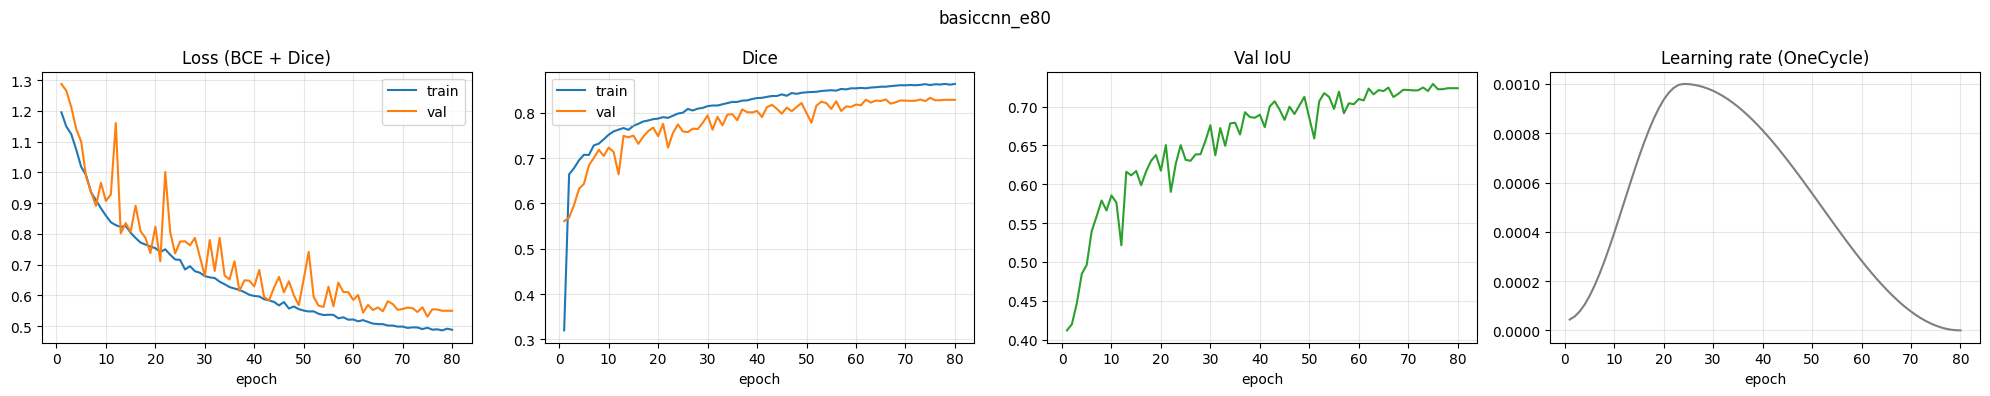

In [6]:
hist = pd.read_csv(HISTORY_PATH)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].plot(hist.epoch, hist.train_loss, label="train"); axes[0].plot(hist.epoch, hist.val_loss, label="val")
axes[0].set_title("Loss (BCE + Dice)"); axes[0].legend()
axes[1].plot(hist.epoch, hist.train_dice, label="train"); axes[1].plot(hist.epoch, hist.val_dice, label="val")
axes[1].set_title("Dice"); axes[1].legend()
axes[2].plot(hist.epoch, hist.val_iou, color="tab:green"); axes[2].set_title("Val IoU")
axes[3].plot(hist.epoch, hist.lr, color="tab:gray"); axes[3].set_title("Learning rate (OneCycle)")
for a in axes: a.set_xlabel("epoch"); a.grid(alpha=0.3)
fig.suptitle(RUN_TAG)
plt.tight_layout(); plt.savefig(f"outputs/02_{RUN_TAG}_curves.png", dpi=110); plt.show()

## Validation predictions from the best checkpoint

Loaded epoch 75 (val Dice 0.8329)


,dice,iou,acc
species,,,
cat,0.8381,0.7343,0.8603
dog,0.8303,0.7267,0.8719


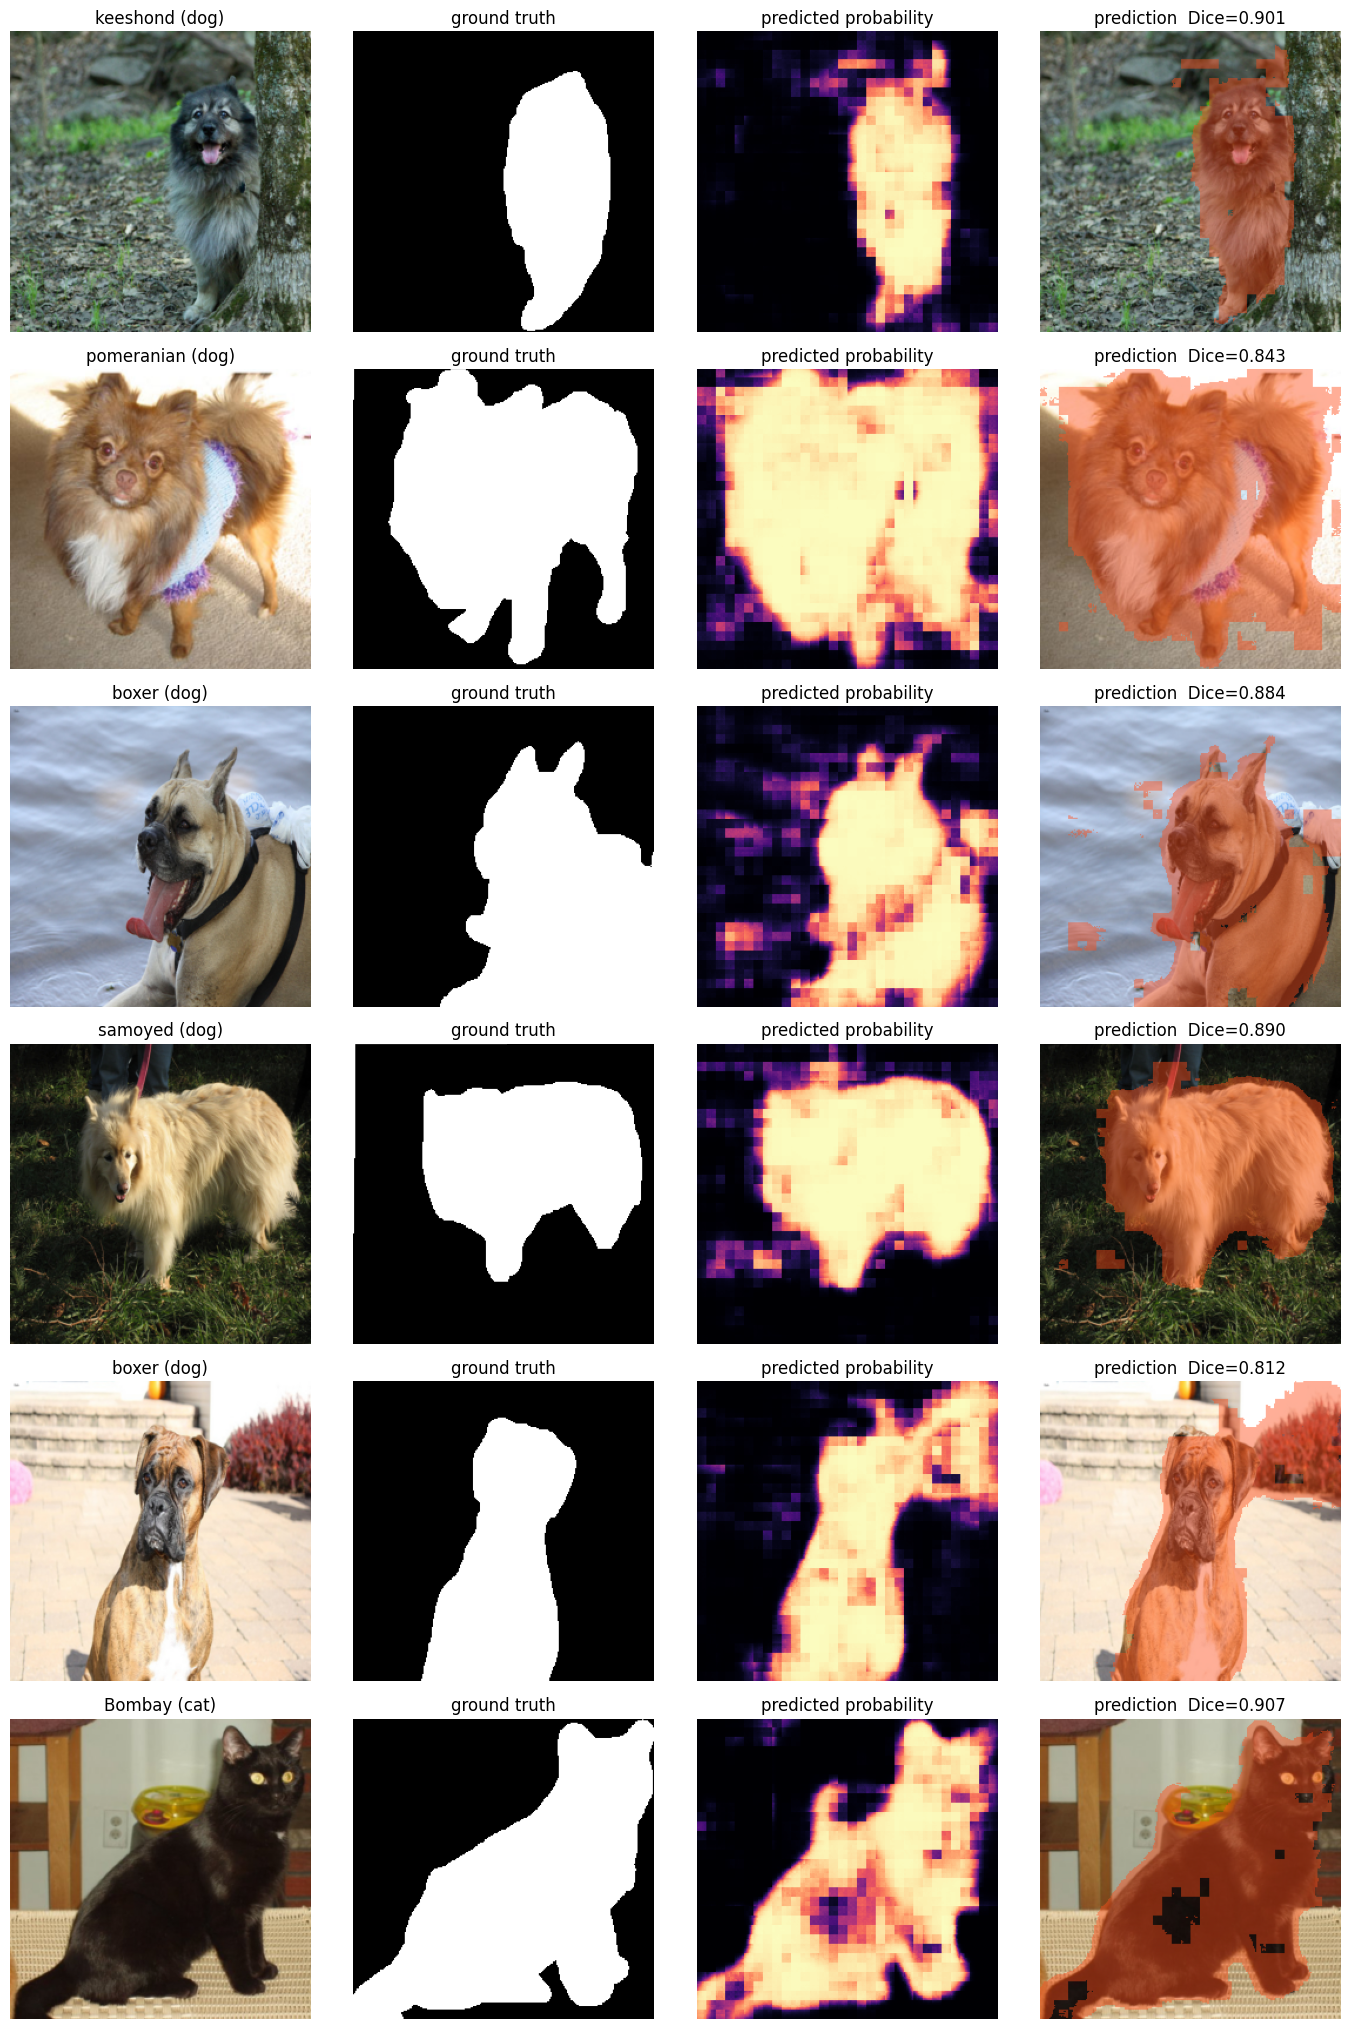

In [7]:
ckpt = torch.load(CKPT_PATH, map_location=device)
model.load_state_dict(ckpt["model"])
print(f"Loaded epoch {ckpt['epoch']} (val Dice {ckpt['val_dice']:.4f})")

val_records = predict_dataset(model, val_loader, device=device, keep_tensors=True)
val_df = pd.DataFrame([{k: v for k, v in r.items() if k in ("species", "dice", "iou", "acc")} for r in val_records])
display(val_df.groupby("species")[["dice", "iou", "acc"]].mean().round(4))

rng = np.random.default_rng(SEED)
show = [val_records[i] for i in rng.choice(len(val_records), 6, replace=False)]
fig, axes = plt.subplots(len(show), 4, figsize=(14, 3.4 * len(show)))
for row, r in zip(axes, show):
    img = denormalize(r["image"])
    row[0].imshow(img); row[0].set_title(f"{r['breed']} ({r['species']})")
    row[1].imshow(r["mask"], cmap="gray"); row[1].set_title("ground truth")
    row[2].imshow(r["prob"], cmap="magma", vmin=0, vmax=1); row[2].set_title("predicted probability")
    row[3].imshow(overlay(img, r["pred"].numpy())); row[3].set_title(f"prediction  Dice={r['dice']:.3f}")
    for a in row: a.axis("off")
plt.tight_layout(); plt.show()